<h1 style="text-align:center;color:blue;">CIFAR10 Image Classification using CNN</h1>

**A Practice Of Training Neural Network using CNN**

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from matplotlib import pyplot as plt
import numpy as np

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device) 

cuda


In [3]:
# Transformations
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# CIFAR-10 dataset
train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

C:\Users\Trijesh Kondapuram\AppData\Roaming\Python\Python314\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [4]:
print(len(train_dataset), len(test_dataset))

50000 10000


In [16]:
batch_size = 100
#Data Loaders
train_loader =DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader (dataset=test_dataset, batch_size=batch_size, shuffle=False)

In [17]:
for i, (images, labels) in enumerate (train_loader):
    print(images.shape)
    print(labels.shape)
    break

torch.Size([100, 3, 32, 32])
torch.Size([100])


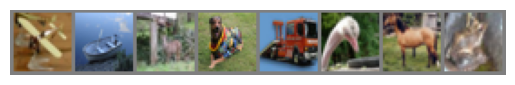

In [18]:
def imshow(img):
    img = img / 2 + 0.5   # unnormalize
    npimg = img.numpy()

    # Correct transpose: (C,H,W) → (H,W,C)
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")
    plt.show()

# Show images
imshow(torchvision.utils.make_grid(images[:8]))


In [19]:
labels[:8]

tensor([0, 8, 4, 5, 9, 2, 7, 6])

In [20]:
class_names =train_dataset.classes


In [21]:
[class_names[i] for i in labels[:8]]

['airplane', 'ship', 'deer', 'dog', 'truck', 'bird', 'horse', 'frog']

In [31]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network=nn.Sequential(
            nn.Conv2d(3,32,kernel_size=(3,3),padding="same"),# output: (32, 32,32)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2)),# output: (32,16,16)
            nn.Conv2d(32,64,kernel_size=(3,3)), # output : (64,14,14)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2)) # output: (64,7,7)
        )
        self.fc_network=nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*7*7,700),
            nn.ReLU(),
            nn.Linear(700,120),
            nn.ReLU(),
            nn.Linear(120,10)
        )
    def forward(self,x):
        x=self.network(x)
        x=self.fc_network(x)
        return x


In [32]:
CNN()

CNN(
  (network): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  )
  (fc_network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=700, bias=True)
    (2): ReLU()
    (3): Linear(in_features=700, out_features=120, bias=True)
    (4): ReLU()
    (5): Linear(in_features=120, out_features=10, bias=True)
  )
)

In [33]:
# Hyperparameters
num_epochs = 10
learning_rate = 0.001

model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [34]:
# Training loop
total_step = len(train_loader)
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        if (i+1) % 100 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{total_step}], Loss: {loss.item():.4f}")

# Testing the model
model.eval()
with torch.no_grad():
    correct = 0
    total = 0
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Accuracy of the model on the 10000 test images: {100 * correct / total:.2f}%")

Epoch [1/10], Step [100/500], Loss: 1.6018
Epoch [1/10], Step [200/500], Loss: 1.4126
Epoch [1/10], Step [300/500], Loss: 1.3127
Epoch [1/10], Step [400/500], Loss: 1.3923
Epoch [1/10], Step [500/500], Loss: 0.9677
Epoch [2/10], Step [100/500], Loss: 1.1067
Epoch [2/10], Step [200/500], Loss: 0.9883
Epoch [2/10], Step [300/500], Loss: 0.8764
Epoch [2/10], Step [400/500], Loss: 0.8991
Epoch [2/10], Step [500/500], Loss: 0.8093
Epoch [3/10], Step [100/500], Loss: 0.7208
Epoch [3/10], Step [200/500], Loss: 0.6650
Epoch [3/10], Step [300/500], Loss: 0.7708
Epoch [3/10], Step [400/500], Loss: 0.6150
Epoch [3/10], Step [500/500], Loss: 0.6674
Epoch [4/10], Step [100/500], Loss: 0.5035
Epoch [4/10], Step [200/500], Loss: 0.6909
Epoch [4/10], Step [300/500], Loss: 0.7079
Epoch [4/10], Step [400/500], Loss: 0.8072
Epoch [4/10], Step [500/500], Loss: 0.4495
Epoch [5/10], Step [100/500], Loss: 0.4883
Epoch [5/10], Step [200/500], Loss: 0.6607
Epoch [5/10], Step [300/500], Loss: 0.4720
Epoch [5/10